Завдання 1

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import os

from tensorflow import keras
from tensorflow.keras import layers

from sklearn.metrics import classification_report
from google.colab import drive

print("Версія TensorFlow:", tf.__version__)
print("GPU доступний:", len(tf.config.list_physical_devices('GPU')) > 0)

Версія TensorFlow: 2.21.0
GPU доступний: True


Підключення Google Drive

In [3]:
drive.mount('/content/drive')

save_dir = '/content/drive/MyDrive/Laboratorna_8'

os.makedirs(save_dir, exist_ok=True)

print("Папку для збереження результатів створено!")

Mounted at /content/drive
Папку для збереження результатів створено!


Завантаження датасету Fashion-MNIST

In [4]:
(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

print("Розмір тренувальної вибірки:", x_train.shape)
print("Розмір тестової вибірки:", x_test.shape)

print("Кількість тренувальних зображень:", len(x_train))
print("Кількість тестових зображень:", len(x_test))

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Розмір тренувальної вибірки: (60000, 28, 28)
Розмір тестової вибірки: (10000, 28, 28)
Кількість тренувальних зображень: 60000
Кількість тестових зображень: 10000


Виведення 10 зображень

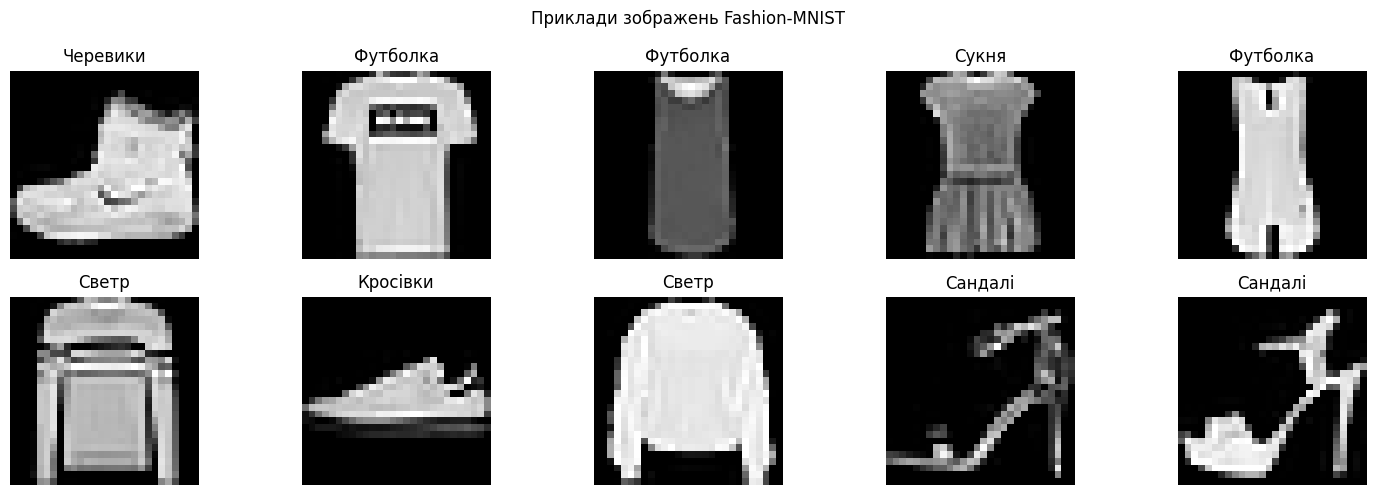

In [5]:
class_names = [
    'Футболка',
    'Штани',
    'Светр',
    'Сукня',
    'Пальто',
    'Сандалі',
    'Сорочка',
    'Кросівки',
    'Сумка',
    'Черевики'
]

plt.figure(figsize=(15, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(class_names[y_train[i]])
    plt.axis('off')

plt.suptitle('Приклади зображень Fashion-MNIST')
plt.tight_layout()
plt.show()

Підготовка даних

In [6]:
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

x_train = x_train.reshape(-1, 28 * 28)
x_test = x_test.reshape(-1, 28 * 28)

print("Розмір тренувальних даних:", x_train.shape)
print("Розмір тестових даних:", x_test.shape)

print("Мінімальне значення:", x_train.min())
print("Максимальне значення:", x_train.max())

Розмір тренувальних даних: (60000, 784)
Розмір тестових даних: (10000, 784)
Мінімальне значення: 0.0
Максимальне значення: 1.0


Побудова архітектури нейронної мережі

In [7]:
model = keras.Sequential([
    layers.Input(shape=(784,)),

    layers.Dense(256, activation='relu'),
    layers.Dropout(0.3),

    layers.Dense(128, activation='relu'),
    layers.Dropout(0.2),

    layers.Dense(64, activation='relu'),

    layers.Dense(10, activation='softmax')
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Архітектуру нейронної мережі створено!")

Архітектуру нейронної мережі створено!


Використання ранньої зупинки та зменшення швидкості навчання


In [8]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=4,
    restore_best_weights=True
)

reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=0.00001
)

callbacks_list = [early_stopping, reduce_lr]

print("Механізми запобігання перенавчанню налаштовано!")

Механізми запобігання перенавчанню налаштовано!


Навчання нейронної мережі

In [9]:
history = model.fit(
    x_train,
    y_train,
    epochs=15,
    batch_size=128,
    validation_split=0.1,
    callbacks=callbacks_list,
    verbose=1
)

Epoch 1/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.7746 - loss: 0.6251 - val_accuracy: 0.8432 - val_loss: 0.4148 - learning_rate: 0.0010
Epoch 2/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8450 - loss: 0.4323 - val_accuracy: 0.8580 - val_loss: 0.3820 - learning_rate: 0.0010
Epoch 3/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8585 - loss: 0.3903 - val_accuracy: 0.8730 - val_loss: 0.3493 - learning_rate: 0.0010
Epoch 4/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8637 - loss: 0.3725 - val_accuracy: 0.8765 - val_loss: 0.3439 - learning_rate: 0.0010
Epoch 5/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8674 - loss: 0.3550 - val_accuracy: 0.8758 - val_loss: 0.3338 - learning_rate: 0.0010
Epoch 6/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8744 - loss: 0.3400 - val_accuracy: 0.8780 - val_loss: 0.3288 - learning_rate: 0.0010
Epoch 7/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8786 - loss: 0.3294 -

Виведення архітектури моделі

In [10]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 728,288 (2.78 MB)

 Trainable params: 242,762 (948.29 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 485,526 (1.85 MB)

Збереження моделі на Google Drive

In [11]:
model_path = os.path.join(save_dir, 'fashion_mnist_model.keras')

model.save(model_path)

print("Модель успішно збережено!")
print("Шлях до моделі:", model_path)

Модель успішно збережено!
Шлях до моделі: /content/drive/MyDrive/Laboratorna_8/fashion_mnist_model.keras


Оцінювання моделі на тестових даних

In [12]:
test_loss, test_accuracy = model.evaluate(
    x_test,
    y_test,
    verbose=1
)

print("\nРезультати оцінювання:")
print("Функція втрат:", round(test_loss, 4))
print("Точність:", round(test_accuracy * 100, 2), "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.8899 - loss: 0.3189

Результати оцінювання:
Функція втрат: 0.3189
Точність: 88.99 %


Побудова графіків точності та функції втрат

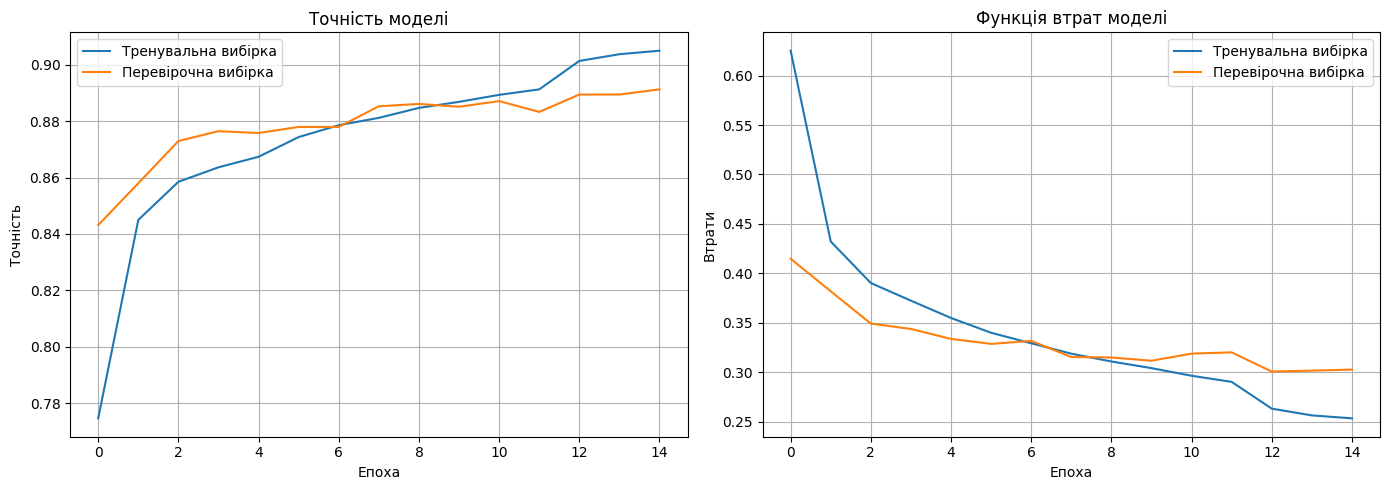

In [13]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)

plt.plot(history.history['accuracy'], label='Тренувальна вибірка')
plt.plot(history.history['val_accuracy'], label='Перевірочна вибірка')

plt.title('Точність моделі')
plt.xlabel('Епоха')
plt.ylabel('Точність')
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)

plt.plot(history.history['loss'], label='Тренувальна вибірка')
plt.plot(history.history['val_loss'], label='Перевірочна вибірка')

plt.title('Функція втрат моделі')
plt.xlabel('Епоха')
plt.ylabel('Втрати')
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

Класифікаційний звіт

In [14]:
y_pred = model.predict(x_test)

y_pred_classes = np.argmax(y_pred, axis=1)

print("Класифікаційний звіт:")

print(classification_report(
    y_test,
    y_pred_classes,
    target_names=class_names,
    digits=4
))

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step
Класифікаційний звіт:
              precision    recall  f1-score   support

    Футболка     0.8289    0.8720    0.8499      1000
       Штани     0.9848    0.9710    0.9778      1000
       Светр     0.7778    0.8260    0.8012      1000
       Сукня     0.8628    0.9180    0.8895      1000
      Пальто     0.8100    0.7970    0.8034      1000
     Сандалі     0.9818    0.9700    0.9759      1000
     Сорочка     0.7671    0.6520    0.7049      1000
    Кросівки     0.9294    0.9740    0.9512      1000
       Сумка     0.9779    0.9750    0.9765      1000
    Черевики     0.9742    0.9440    0.9589      1000

    accuracy                         0.8899     10000
   macro avg     0.8895    0.8899    0.8889     10000
weighted avg     0.8895    0.8899    0.8889     10000



Результати розпізнавання

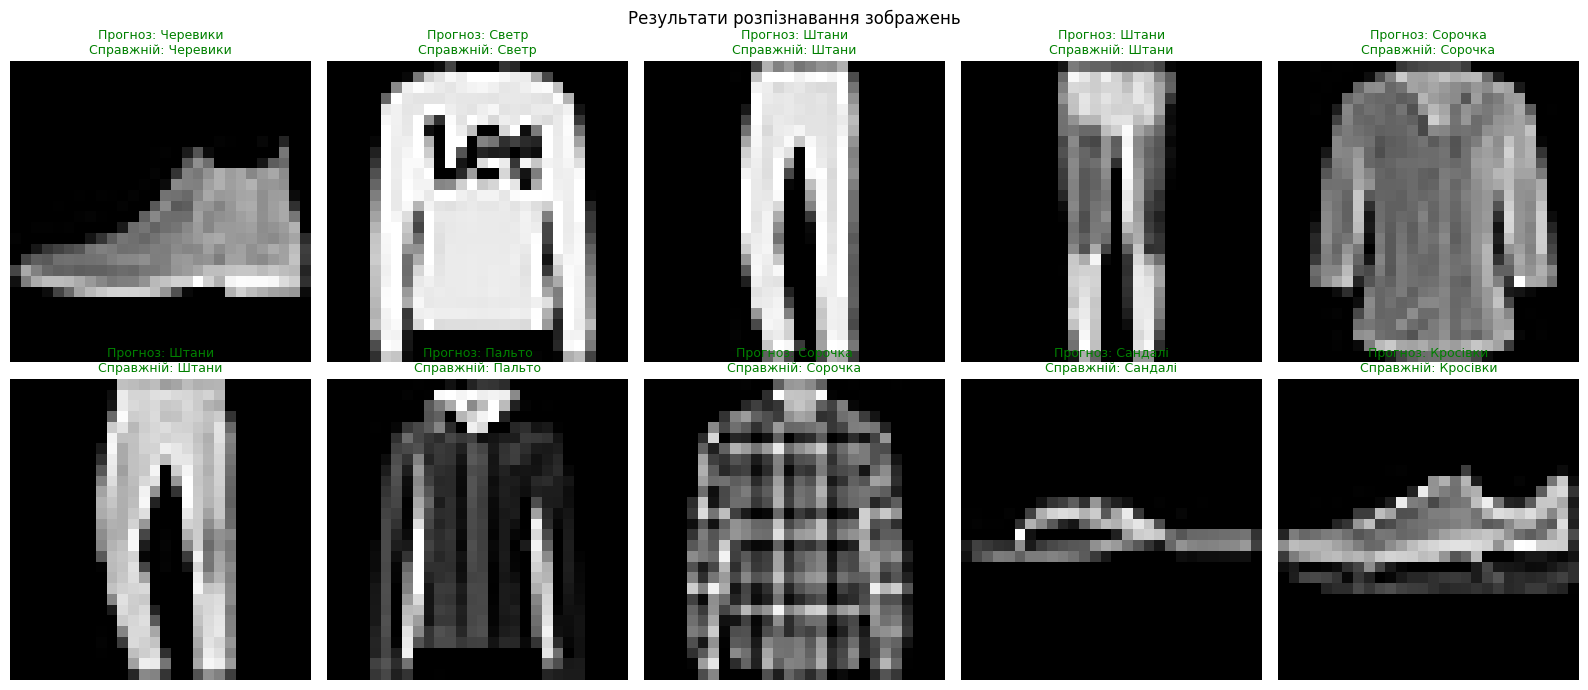

In [15]:
plt.figure(figsize=(16, 7))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    plt.imshow(x_test[i].reshape(28, 28), cmap='gray')

    predicted_class = class_names[y_pred_classes[i]]
    true_class = class_names[y_test[i]]

    color = 'green' if y_pred_classes[i] == y_test[i] else 'red'

    plt.title(
        f'Прогноз: {predicted_class}\nСправжній: {true_class}',
        color=color,
        fontsize=9
    )

    plt.axis('off')

plt.suptitle('Результати розпізнавання зображень')
plt.tight_layout()
plt.show()

Завдання 2

Встановлення та імпорт Keras Tuner

In [16]:
!pip install -q keras-tuner

In [17]:
import keras_tuner as kt

print("Keras Tuner успішно підключено!")

Keras Tuner успішно підключено!


Створення функції побудови моделі

In [18]:
def build_model(hp):

    model = keras.Sequential()

    model.add(layers.Input(shape=(784,)))

    num_layers = hp.Int(
        'num_layers',
        min_value=1,
        max_value=3,
        step=1
    )

    for i in range(num_layers):

        units = hp.Choice(
            f'units_{i}',
            values=[64, 128, 256]
        )

        model.add(
            layers.Dense(
                units=units,
                activation='relu'
            )
        )

        dropout_rate = hp.Choice(
            f'dropout_{i}',
            values=[0.1, 0.2, 0.3]
        )

        model.add(layers.Dropout(dropout_rate))

    model.add(layers.Dense(10, activation='softmax'))

    learning_rate = hp.Choice(
        'learning_rate',
        values=[0.001, 0.0005, 0.0001]
    )

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model


print("Функцію побудови моделі створено!")

Функцію побудови моделі створено!


Налаштування Keras Tuner

In [19]:
tuner = kt.RandomSearch(
    build_model,
    objective='val_accuracy',
    max_trials=10,
    executions_per_trial=1,
    directory=os.path.join(save_dir, 'keras_tuner'),
    project_name='fashion_mnist_tuning',
    overwrite=True
)

print("Keras Tuner налаштовано!")

Keras Tuner налаштовано!


Пошук найкращих гіперпараметрів

In [20]:
tuner.search(
    x_train,
    y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.1,
    callbacks=[
        keras.callbacks.EarlyStopping(
            monitor='val_loss',
            patience=3,
            restore_best_weights=True
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss',
            factor=0.5,
            patience=2,
            min_lr=0.00001
        )
    ],
    verbose=1
)

print("Пошук гіперпараметрів завершено!")

Trial 10 Complete [00h 00m 19s]
val_accuracy: 0.8841666579246521

Best val_accuracy So Far: 0.8899999856948853
Total elapsed time: 00h 03m 57s
Пошук гіперпараметрів завершено!


Отримання найкращих гіперпараметрів

In [21]:
best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]

print("Найкращі гіперпараметри:")

print("Кількість прихованих шарів:",
      best_hp.get('num_layers'))

print("Швидкість навчання:",
      best_hp.get('learning_rate'))

for i in range(best_hp.get('num_layers')):
    print(
        f"Шар {i + 1}:",
        best_hp.get(f'units_{i}'),
        "нейронів"
    )

    print(
        f"Dropout шару {i + 1}:",
        best_hp.get(f'dropout_{i}')
    )

Найкращі гіперпараметри:
Кількість прихованих шарів: 1
Швидкість навчання: 0.001
Шар 1: 128 нейронів
Dropout шару 1: 0.1


Створення та навчання найкращої моделі

In [22]:
best_model = tuner.hypermodel.build(best_hp)

history_tuned = best_model.fit(
    x_train,
    y_train,
    epochs=15,
    batch_size=128,
    validation_split=0.1,
    callbacks=[
        keras.callbacks.EarlyStopping(
            monitor='val_loss',
            patience=4,
            restore_best_weights=True
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss',
            factor=0.5,
            patience=2,
            min_lr=0.00001
        )
    ],
    verbose=1
)

print("Найкращу модель навчено!")

Epoch 1/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.7965 - loss: 0.5903 - val_accuracy: 0.8487 - val_loss: 0.4345 - learning_rate: 0.0010
Epoch 2/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8516 - loss: 0.4208 - val_accuracy: 0.8587 - val_loss: 0.3917 - learning_rate: 0.0010
Epoch 3/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8657 - loss: 0.3751 - val_accuracy: 0.8680 - val_loss: 0.3644 - learning_rate: 0.0010
Epoch 4/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8746 - loss: 0.3493 - val_accuracy: 0.8728 - val_loss: 0.3456 - learning_rate: 0.0010
Epoch 5/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8804 - loss: 0.3318 - val_accuracy: 0.8760 - val_loss: 0.3349 - learning_rate: 0.0010
Epoch 6/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8850 - loss: 0.3159 - val_accuracy: 0.8815 - val_loss: 0.3289 - learning_rate: 0.0010
Epoch 7/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8895 - loss: 0.3055 - 

Виведення архітектури найкращої моделі

In [23]:
best_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 305,312 (1.16 MB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 203,542 (795.09 KB)

Збереження найкращої моделі

In [24]:
best_model_path = os.path.join(
    save_dir,
    'fashion_mnist_best_model.keras'
)

best_model.save(best_model_path)

print("Найкращу модель збережено!")
print("Шлях:", best_model_path)

Найкращу модель збережено!
Шлях: /content/drive/MyDrive/Laboratorna_8/fashion_mnist_best_model.keras


Оцінювання найкращої моделі

In [25]:
tuned_test_loss, tuned_test_accuracy = best_model.evaluate(
    x_test,
    y_test,
    verbose=1
)

print("\nРезультати найкращої моделі:")
print("Функція втрат:", round(tuned_test_loss, 4))
print("Точність:", round(tuned_test_accuracy * 100, 2), "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8840 - loss: 0.3252

Результати найкращої моделі:
Функція втрат: 0.3252
Точність: 88.4 %


Побудова графіків найкращої моделі

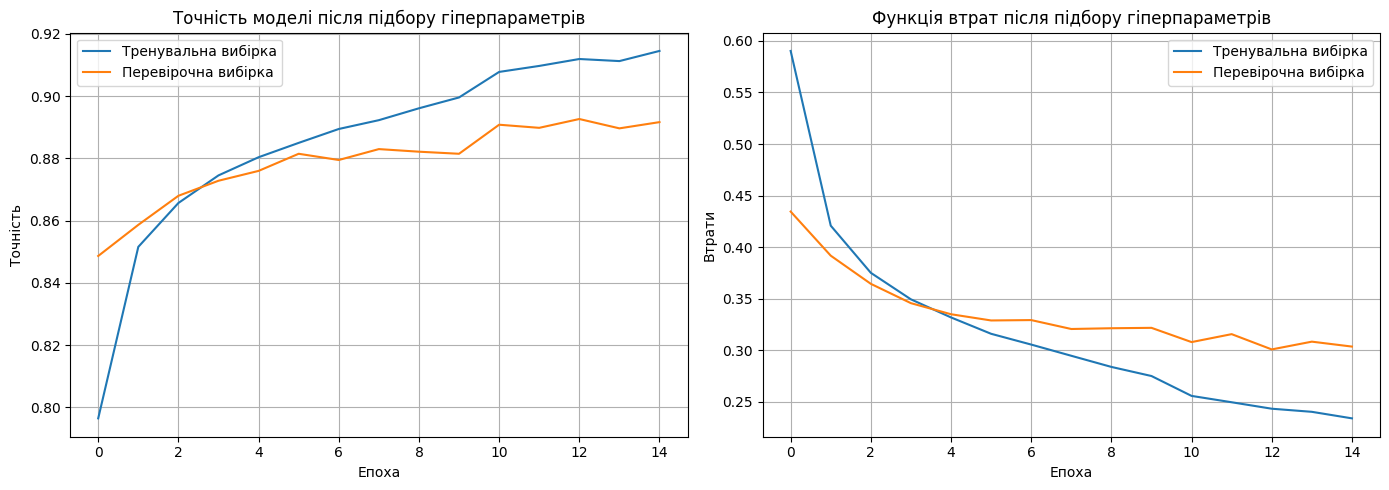

In [26]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)

plt.plot(
    history_tuned.history['accuracy'],
    label='Тренувальна вибірка'
)

plt.plot(
    history_tuned.history['val_accuracy'],
    label='Перевірочна вибірка'
)

plt.title('Точність моделі після підбору гіперпараметрів')
plt.xlabel('Епоха')
plt.ylabel('Точність')
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)

plt.plot(
    history_tuned.history['loss'],
    label='Тренувальна вибірка'
)

plt.plot(
    history_tuned.history['val_loss'],
    label='Перевірочна вибірка'
)

plt.title('Функція втрат після підбору гіперпараметрів')
plt.xlabel('Епоха')
plt.ylabel('Втрати')
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

Класифікаційний звіт найкращої моделі

In [27]:
y_pred_tuned = best_model.predict(x_test)

y_pred_tuned_classes = np.argmax(y_pred_tuned, axis=1)

print("Класифікаційний звіт найкращої моделі:")

print(classification_report(
    y_test,
    y_pred_tuned_classes,
    target_names=class_names,
    digits=4
))

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
Класифікаційний звіт найкращої моделі:
              precision    recall  f1-score   support

    Футболка     0.8337    0.8520    0.8427      1000
       Штани     0.9918    0.9730    0.9823      1000
       Светр     0.8161    0.7590    0.7865      1000
       Сукня     0.9070    0.8780    0.8923      1000
      Пальто     0.7831    0.8340    0.8077      1000
     Сандалі     0.9737    0.9630    0.9683      1000
     Сорочка     0.6810    0.7110    0.6957      1000
    Кросівки     0.9577    0.9280    0.9426      1000
       Сумка     0.9808    0.9690    0.9748      1000
    Черевики     0.9320    0.9730    0.9521      1000

    accuracy                         0.8840     10000
   macro avg     0.8857    0.8840    0.8845     10000
weighted avg     0.8857    0.8840    0.8845     10000



Результати розпізнавання найкращої моделі

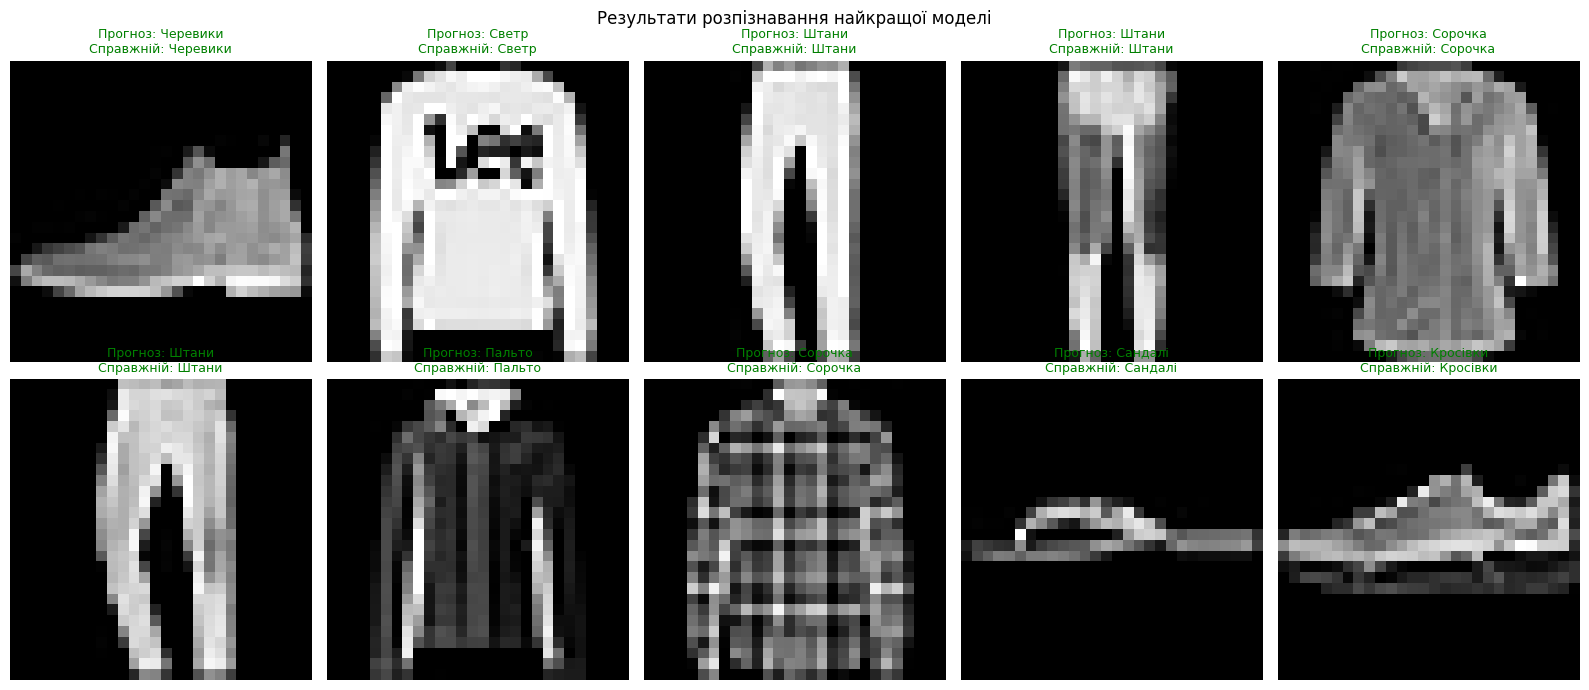

In [28]:
plt.figure(figsize=(16, 7))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    plt.imshow(x_test[i].reshape(28, 28), cmap='gray')

    predicted_class = class_names[y_pred_tuned_classes[i]]
    true_class = class_names[y_test[i]]

    color = (
        'green'
        if y_pred_tuned_classes[i] == y_test[i]
        else 'red'
    )

    plt.title(
        f'Прогноз: {predicted_class}\nСправжній: {true_class}',
        color=color,
        fontsize=9
    )

    plt.axis('off')

plt.suptitle('Результати розпізнавання найкращої моделі')
plt.tight_layout()
plt.show()

Порівняння точності та функції втрат

In [29]:
print("ПОРІВНЯННЯ РЕЗУЛЬТАТІВ МОДЕЛЕЙ")
print("-" * 60)

print(f"{'Показник':<30} {'Звичайна модель':<18} {'Keras Tuner'}")
print("-" * 60)

print(
    f"{'Точність':<30} "
    f"{test_accuracy:<18.4f} "
    f"{tuned_test_accuracy:.4f}"
)

print(
    f"{'Функція втрат':<30} "
    f"{test_loss:<18.4f} "
    f"{tuned_test_loss:.4f}"
)

print("-" * 60)

if tuned_test_accuracy > test_accuracy:
    print("Краща модель за точністю: модель з Keras Tuner")
elif tuned_test_accuracy < test_accuracy:
    print("Краща модель за точністю: звичайна модель")
else:
    print("Обидві моделі мають однакову точність")

ПОРІВНЯННЯ РЕЗУЛЬТАТІВ МОДЕЛЕЙ
------------------------------------------------------------
Показник                       Звичайна модель    Keras Tuner
------------------------------------------------------------
Точність                       0.8899             0.8840
Функція втрат                  0.3189             0.3252
------------------------------------------------------------
Краща модель за точністю: звичайна модель


Візуальне порівняння моделей

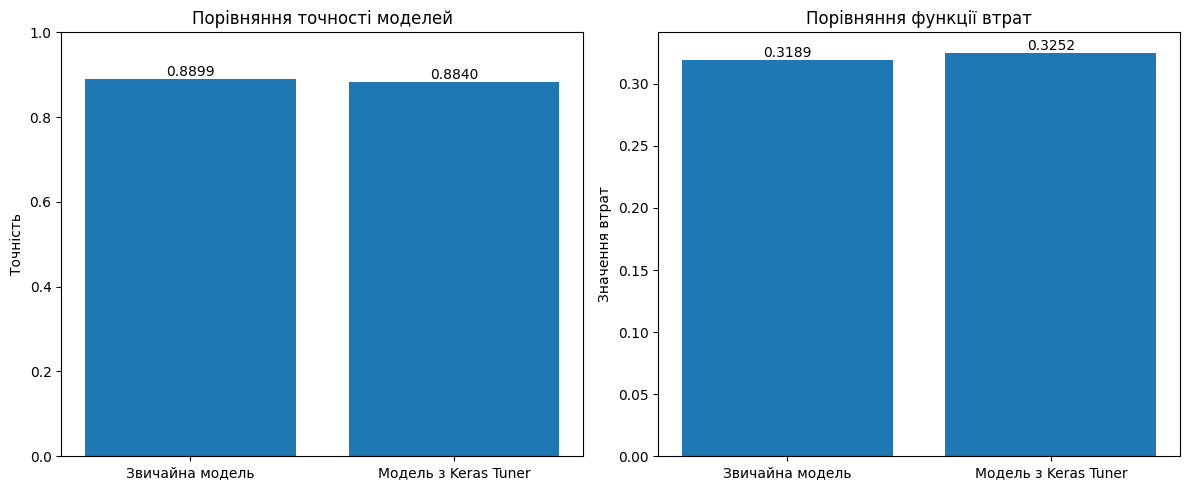

In [30]:
models_names = ['Звичайна модель', 'Модель з Keras Tuner']

accuracies = [
    test_accuracy,
    tuned_test_accuracy
]

losses = [
    test_loss,
    tuned_test_loss
]

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

bars = plt.bar(models_names, accuracies)

plt.title('Порівняння точності моделей')
plt.ylabel('Точність')
plt.ylim(0, 1)

for bar, value in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{value:.4f}',
        ha='center',
        va='bottom'
    )

plt.subplot(1, 2, 2)

bars = plt.bar(models_names, losses)

plt.title('Порівняння функції втрат')
plt.ylabel('Значення втрат')

for bar, value in zip(bars, losses):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{value:.4f}',
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.show()

Збереження результатів порівняння

In [31]:
results_path = os.path.join(save_dir, 'results.txt')

with open(results_path, 'w', encoding='utf-8') as file:

    file.write("Результати лабораторної роботи № 8\n\n")

    file.write("Звичайна нейронна мережа:\n")
    file.write(f"Точність: {test_accuracy:.4f}\n")
    file.write(f"Функція втрат: {test_loss:.4f}\n\n")

    file.write("Нейронна мережа з Keras Tuner:\n")
    file.write(f"Точність: {tuned_test_accuracy:.4f}\n")
    file.write(f"Функція втрат: {tuned_test_loss:.4f}\n\n")

    file.write("Найкращі гіперпараметри:\n")
    file.write(f"Кількість шарів: {best_hp.get('num_layers')}\n")
    file.write(f"Швидкість навчання: {best_hp.get('learning_rate')}\n")

print("Результати збережено у Google Drive!")
print(results_path)

Результати збережено у Google Drive!
/content/drive/MyDrive/Laboratorna_8/results.txt


Висновок: Під час виконання лабораторної роботи було розглянуто процес розробки та навчання багатошарових нейронних мереж із використанням бібліотеки Keras. У першому завданні було завантажено датасет Fashion-MNIST, який містить зображення десяти категорій одягу та взуття. Було виконано попередню обробку даних, нормалізацію значень пікселів та побудовано багатошарову нейронну мережу. Для запобігання перенавчанню використано механізми EarlyStopping та ReduceLROnPlateau. Після навчання моделі було побудовано графіки точності та функції втрат, сформовано класифікаційний звіт і перевірено результати розпізнавання зображень. У другому завданні було створено нейронну мережу з використанням Keras Tuner. За допомогою алгоритму RandomSearch здійснено автоматичний підбір гіперпараметрів, зокрема кількості прихованих шарів, кількості нейронів, значень Dropout та швидкості навчання. Після навчання обох моделей було проведено порівняння їхньої точності та функції втрат на тестових даних. Це дозволило визначити ефективність автоматичного підбору гіперпараметрів.

У результаті виконання лабораторної роботи було отримано практичні навички роботи з бібліотекою Keras, створення багатошарових нейронних мереж, налаштування процесу навчання, оцінювання якості класифікації та використання Keras Tuner для оптимізації моделей.